# Readability Metrics Across LLM Summary Types

This notebook computes readability metrics for all summary variants across the three LLMs (`gpt`, `phi`, `qwen`).

Metrics:
- SMOG (Simple Measure of Gobbledygook)
- Flesch-Kincaid Grade Level (FKGL)
- Automated Readability Index (ARI)
- Dale-Chall Readability Score
- MTLD (Measure of Textual Lexical Diversity)
- Average Dependency Tree Depth
- Subordinate Clause Ratio

In [ ]:
from pathlib import Path
import json
import sys
import subprocess
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import textstat
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "textstat"])
    import textstat

try:
    import spacy
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "spacy"])
    import spacy

try:
    import scispacy
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scispacy", "--no-deps"])
    import scispacy

try:
    import scipy
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scipy"])
    import scipy

try:
    import nmslib
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "nmslib-metabrainz==2.1.3"])
    import nmslib

!python -m spacy download en_core_web_sm


sns.set_theme(style="whitegrid")

In [ ]:
BASE_DIR = Path("data/generated_summaries")
MODEL_DIRS = ["gpt", "phi", "qwen"]
SUMMARY_FILES = {
    "base": "menstrual_health_patient_summaries.json",
    "constrained": "menstrual_health_patient_summaries_constrained.json",
    "rag_constrained": "menstrual_health_patient_summaries_rag_constrained.json",
}

def safe_metric(metric_fn, text):
    try:
        value = metric_fn(text)
        return float(value)
    except Exception:
        return np.nan

def tokenize_words(text):
    return re.findall(r"\b[a-zA-Z]+(?:'[a-zA-Z]+)?\b", text.lower())

def mtld_directional(tokens, threshold=0.72):
    if not tokens:
        return np.nan

    factors = 0.0
    token_count = 0
    types = set()

    for token in tokens:
        token_count += 1
        types.add(token)
        current_ttr = len(types) / token_count
        if current_ttr <= threshold:
            factors += 1.0
            token_count = 0
            types.clear()

    if token_count > 0:
        current_ttr = len(types) / token_count
        if current_ttr < 1.0:
            factors += (1.0 - current_ttr) / (1.0 - threshold)

    if factors == 0:
        # Very high lexical diversity without threshold crossing.
        return float(len(tokens))

    return float(len(tokens) / factors)

def mtld(text, threshold=0.72):
    tokens = tokenize_words(text)
    if not tokens:
        return np.nan

    forward_score = mtld_directional(tokens, threshold=threshold)
    backward_score = mtld_directional(list(reversed(tokens)), threshold=threshold)
    return float(np.nanmean([forward_score, backward_score]))

def dependency_tree_depth(token):
    child_depths = [dependency_tree_depth(child) for child in token.children]
    return 1 + max(child_depths, default=0)

def get_syntax_nlp():
    for model_name in ("en_core_sci_sm", "en_core_web_sm"):
        try:
            nlp_model = spacy.load(model_name)
            loaded_meta_name = nlp_model.meta.get("name", model_name)
            print(f"[syntax_nlp] loaded spaCy model request={model_name}, resolved={loaded_meta_name}")
            if ("parser" not in nlp_model.pipe_names
                and "senter" not in nlp_model.pipe_names
                and "sentencizer" not in nlp_model.pipe_names):
                nlp_model.add_pipe("sentencizer")
            return nlp_model, loaded_meta_name
        except Exception as e:
            print(f"[syntax_nlp] FAILED to load {model_name}: {type(e).__name__}: {e}")
            continue
    return None, None

def syntactic_features(text, nlp_model):
    if nlp_model is None:
        return np.nan, np.nan

    doc = nlp_model(text)
    sents = [sent for sent in doc.sents if sent.text.strip()]
    if not sents:
        return np.nan, np.nan

    subordinate_deps = {"advcl", "ccomp", "xcomp", "acl", "relcl", "csubj", "csubjpass"}
    total_subordinate = 0
    sent_depths = []

    for sent in sents:
        roots = [tok for tok in sent if tok.head == tok]
        if roots:
            sent_depths.append(max(dependency_tree_depth(root) for root in roots))
        total_subordinate += sum(1 for tok in sent if tok.dep_.lower() in subordinate_deps)

    avg_dep_depth = float(np.mean(sent_depths)) if sent_depths else np.nan
    subordinate_clause_ratio = total_subordinate / len(sents)
    return avg_dep_depth, float(subordinate_clause_ratio)

syntax_nlp, syntax_model_name = get_syntax_nlp()
if syntax_nlp is None:
    print("Warning: no spaCy parser model found; syntactic metrics will be NaN.")
else:
    assert syntax_model_name in {"core_sci_sm", "core_web_sm", "en_core_sci_sm", "en_core_web_sm"}, (
        f"Unexpected syntax model: {syntax_model_name}"
    )
    print(f"[syntax_nlp] using one fixed model for all rows: {syntax_model_name}")

rows = []
for model in MODEL_DIRS:
    model_dir = BASE_DIR / model
    for summary_type, file_name in SUMMARY_FILES.items():
        file_path = model_dir / file_name
        if not file_path.exists():
            print(f"Skipping missing file: {file_path}")
            continue

        with file_path.open("r", encoding="utf-8") as f:
            records = json.load(f)

        for rec in records:
            if not isinstance(rec, dict):
                continue

            text = rec.get("patient_summary")
            if not isinstance(text, str) or not text.strip():
                continue

            if syntax_nlp is not None:
                current_model_name = syntax_nlp.meta.get("name", "")
                assert current_model_name == syntax_model_name, (
                    f"Syntax model changed during run: expected {syntax_model_name}, got {current_model_name}"
                )

            avg_dep_depth, subordinate_clause_ratio = syntactic_features(text, syntax_nlp)

            rows.append({
                "model": model,
                "summary_type": summary_type,
                "file_name": file_name,
                "sample_id": rec.get("sample_id"),
                "smog": safe_metric(textstat.smog_index, text),
                "fkgl": safe_metric(textstat.flesch_kincaid_grade, text),
                "ari": safe_metric(textstat.automated_readability_index, text),
                "dale_chall": safe_metric(textstat.dale_chall_readability_score, text),
                "mtld": safe_metric(mtld, text),
                "avg_dep_depth": avg_dep_depth,
                "subordinate_clause_ratio": subordinate_clause_ratio,
                "word_count": safe_metric(textstat.lexicon_count, text),
            })

df = pd.DataFrame(rows)
print(f"Total summaries analyzed: {len(df)}")
df.head()

Pooled correlation matrix across 7 metrics:


,smog,fkgl,ari,dale_chall,mtld,avg_dep_depth,subordinate_clause_ratio
smog,1.000,0.930,0.870,0.505,0.356,0.570,0.426
fkgl,0.930,1.000,0.967,0.435,0.443,0.674,0.539
ari,0.870,0.967,1.000,0.363,0.522,0.705,0.600
dale_chall,0.505,0.435,0.363,1.000,-0.099,0.102,-0.117
mtld,0.356,0.443,0.522,-0.099,1.000,0.455,0.524
avg_dep_depth,0.570,0.674,0.705,0.102,0.455,1.000,0.701
subordinate_clause_ratio,0.426,0.539,0.600,-0.117,0.524,0.701,1.000



Grade-level submatrix (SMOG, FKGL, ARI):


,smog,fkgl,ari
smog,1.00,0.930,0.870
fkgl,0.93,1.000,0.967
ari,0.87,0.967,1.000



Pairwise grade-level correlations:
  smog-fkgl: 0.930
  smog-ari: 0.870
  fkgl-ari: 0.967

Interpretation: At least one grade-level pair is <=0.90. Reconsider treating SMOG/FKGL/ARI as interchangeable.


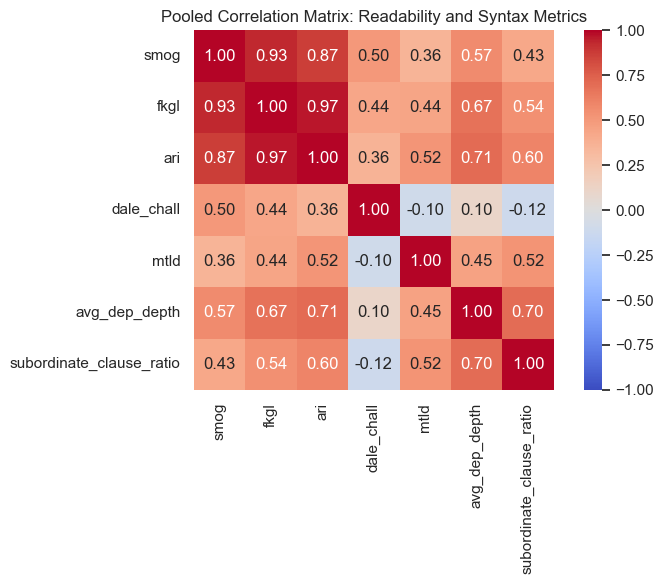

In [3]:
# Pooled collinearity check across readability/syntax metrics.
corr_metrics = [
    "smog",
    "fkgl",
    "ari",
    "dale_chall",
    "mtld",
    "avg_dep_depth",
    "subordinate_clause_ratio",
]

corr_df = df[corr_metrics].copy()
corr_matrix = corr_df.corr(numeric_only=True)

print("Pooled correlation matrix across 7 metrics:")
display(corr_matrix.round(3))

grade_corr = corr_matrix.loc[["smog", "fkgl", "ari"], ["smog", "fkgl", "ari"]]
print("\nGrade-level submatrix (SMOG, FKGL, ARI):")
display(grade_corr.round(3))

pairs = [
    ("smog", "fkgl"),
    ("smog", "ari"),
    ("fkgl", "ari"),
]
pair_corr = {f"{a}-{b}": float(corr_matrix.loc[a, b]) for a, b in pairs}

print("\nPairwise grade-level correlations:")
for k, v in pair_corr.items():
    print(f"  {k}: {v:.3f}")

high_collinearity = all(abs(v) > 0.90 for v in pair_corr.values())
if high_collinearity:
    print(
        "\nInterpretation: SMOG/FKGL/ARI are highly collinear (>0.90 pairwise). "
        "Treat FKGL as the primary readability endpoint and SMOG/ARI as robustness checks."
    )
else:
    print(
        "\nInterpretation: At least one grade-level pair is <=0.90. "
        "Reconsider treating SMOG/FKGL/ARI as interchangeable."
    )

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pooled Correlation Matrix: Readability and Syntax Metrics")
plt.tight_layout()
plt.show()

### Collinearity Note: SMOG, FKGL, and ARI

On pooled data, the grade-level metrics are strongly correlated but not perfectly interchangeable:
- SMOG-FKGL: 0.93
- FKGL-ARI: 0.97
- SMOG-ARI: 0.87

Interpretation for reporting:
- We treat **FKGL** as the primary readability endpoint (most commonly used in patient-education reporting).
- We treat **SMOG** and **ARI** as robustness checks rather than fully independent evidence streams.
- Because one pair is below 0.90, we avoid claiming complete redundancy across all three grade-level metrics.

In [4]:
summary_stats = (
    df.groupby(["model", "summary_type"], as_index=False)
      .agg(
          n=("sample_id", "count"),
          smog_mean=("smog", "mean"),
          smog_std=("smog", "std"),
          fkgl_mean=("fkgl", "mean"),
          fkgl_std=("fkgl", "std"),
          ari_mean=("ari", "mean"),
          ari_std=("ari", "std"),
          dale_chall_mean=("dale_chall", "mean"),
          dale_chall_std=("dale_chall", "std"),
          mtld_mean=("mtld", "mean"),
          mtld_std=("mtld", "std"),
          avg_dep_depth_mean=("avg_dep_depth", "mean"),
          avg_dep_depth_std=("avg_dep_depth", "std"),
          subordinate_clause_ratio_mean=("subordinate_clause_ratio", "mean"),
          subordinate_clause_ratio_std=("subordinate_clause_ratio", "std"),
          word_count_mean=("word_count", "mean"),
      )
      .sort_values(["summary_type", "model"])
)
summary_stats

,model,summary_type,n,smog_mean,smog_std,fkgl_mean,fkgl_std,ari_mean,ari_std,dale_chall_mean,dale_chall_std,mtld_mean,mtld_std,avg_dep_depth_mean,avg_dep_depth_std,subordinate_clause_ratio_mean,subordinate_clause_ratio_std,word_count_mean
0,gpt,base,500,10.161265,1.335399,7.376139,1.595940,8.350579,2.045077,9.669939,0.746173,103.862706,25.596493,4.908141,0.624487,1.060849,0.497728,82.512
3,phi,base,500,12.219508,1.966243,10.631492,2.968047,12.625559,3.737983,9.844759,0.763922,243.921086,104.026769,6.228298,1.164714,2.303393,1.218427,123.858
6,qwen,base,500,10.505355,1.429450,7.644863,1.633267,8.071110,2.056170,10.072928,0.865244,114.310493,33.950892,4.847815,0.707429,0.933406,0.573662,82.822
1,gpt,constrained,500,12.069443,1.121682,9.932653,1.270886,10.973792,1.594195,10.601507,0.529681,96.462673,21.738274,5.605084,0.550582,1.217335,0.473462,134.340
4,phi,constrained,500,13.664715,1.439439,12.179212,1.758420,14.132590,2.087067,10.441154,0.711714,219.693197,34.185829,6.315897,0.672239,2.035444,0.687144,181.432
7,qwen,constrained,500,12.226191,1.078425,9.720765,1.300268,10.663299,1.549310,11.009096,0.614475,120.853211,30.773572,5.500361,0.588175,1.232323,0.505467,134.924
2,gpt,rag_constrained,500,12.376670,0.904640,10.308341,1.057808,10.826768,1.299709,10.544614,0.479561,85.614730,16.788983,5.613253,0.455739,1.293860,0.453780,176.304
5,phi,rag_constrained,500,13.831568,1.246329,12.323506,1.571773,14.292252,1.884365,10.384202,0.668761,213.285065,28.834677,6.407231,0.608852,1.981045,0.608903,224.342
8,qwen,rag_constrained,500,12.683313,0.874018,10.387462,1.054231,11.637911,1.227177,10.920398,0.561562,115.852087,25.138840,5.548483,0.462238,1.282075,0.404845,174.940


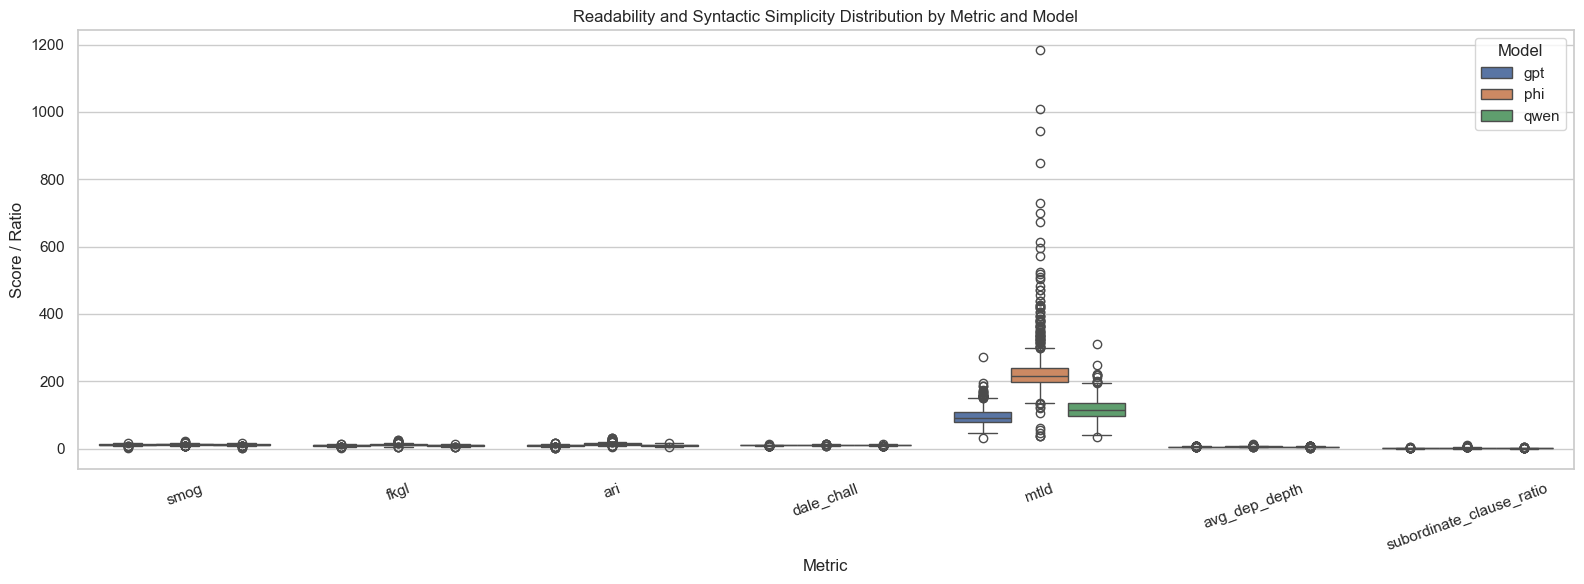

In [5]:
metric_long = df.melt(
    id_vars=["model", "summary_type", "sample_id"],
    value_vars=[
        "smog",
        "fkgl",
        "ari",
        "dale_chall",
        "mtld",
        "avg_dep_depth",
        "subordinate_clause_ratio",
    ],
    var_name="metric",
    value_name="value"
 )

plt.figure(figsize=(16, 6))
sns.boxplot(data=metric_long, x="metric", y="value", hue="model")
plt.title("Readability and Syntactic Simplicity Distribution by Metric and Model")
plt.xlabel("Metric")
plt.ylabel("Score / Ratio")
plt.xticks(rotation=20)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

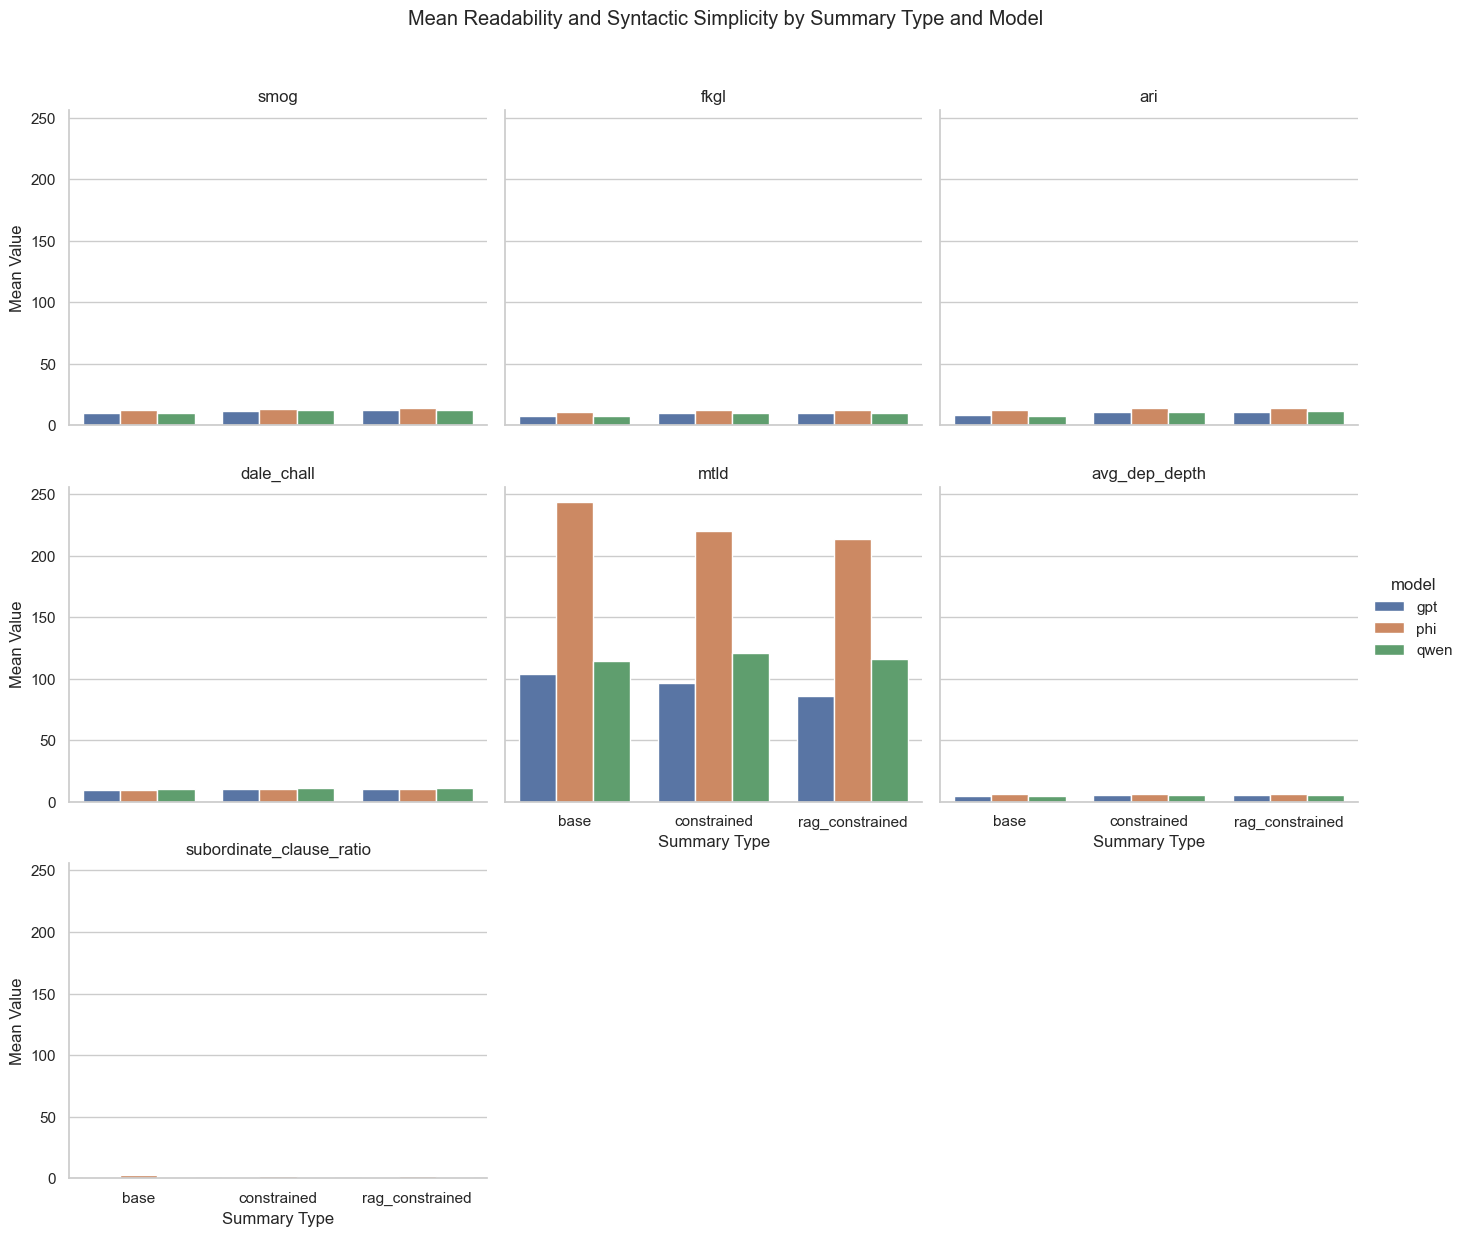

In [6]:
means_long = summary_stats.melt(
    id_vars=["model", "summary_type"],
    value_vars=[
        "smog_mean",
        "fkgl_mean",
        "ari_mean",
        "dale_chall_mean",
        "mtld_mean",
        "avg_dep_depth_mean",
        "subordinate_clause_ratio_mean",
    ],
    var_name="metric",
    value_name="mean_value"
 )
means_long["metric"] = means_long["metric"].str.replace("_mean", "", regex=False)

g = sns.catplot(
    data=means_long,
    kind="bar",
    x="summary_type",
    y="mean_value",
    hue="model",
    col="metric",
    col_wrap=3,
    height=4.2,
    aspect=1.1,
 )
g.set_titles("{col_name}")
g.set_axis_labels("Summary Type", "Mean Value")
g.fig.subplots_adjust(top=0.90)
g.fig.suptitle("Mean Readability and Syntactic Simplicity by Summary Type and Model")
plt.show()

In [7]:
OUTPUT_DIR = Path("data/readability_metrics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

detail_path = OUTPUT_DIR / "readability_per_summary.csv"
agg_path = OUTPUT_DIR / "readability_aggregated.csv"

df.to_csv(detail_path, index=False, encoding="utf-8")
summary_stats.to_csv(agg_path, index=False, encoding="utf-8")

print(f"Saved detailed rows to: {detail_path}")
print(f"Saved aggregated stats to: {agg_path}")

Saved detailed rows to: data\readability_metrics\readability_per_summary.csv
Saved aggregated stats to: data\readability_metrics\readability_aggregated.csv


In [ ]:
import spacy
from scispacy.linking import EntityLinker

# Load the medical model
nlp = spacy.load("en_core_sci_sm")

# Add the UMLS linker to the pipeline
nlp.add_pipe("scispacy_linker", config={"resolve_abbreviations": True, "linker_name": "umls"})

def get_true_medical_jargon(text):
    doc = nlp(text)
    linker = nlp.get_pipe("scispacy_linker")
    
    true_medical_entities = []
    
    for ent in doc.ents:
        # If the entity successfully links to a UMLS concept, it is strictly medical
        if len(ent._.kb_ents) > 0:
            true_medical_entities.append(ent.text)
            
    return true_medical_entities

Loading NLP model with UMLS linker...


,model,summary_type,jargon_density_mean,medical_entity_count_mean,entities_per_sentence_mean,sentence_count_mean
0,gpt,base,19.262812,16.630,3.507100,4.798
1,phi,base,18.911338,24.278,5.590119,4.970
2,qwen,base,21.900093,18.378,3.436300,5.336
3,gpt,constrained,18.917066,26.066,3.916731,6.672
4,phi,constrained,17.649440,33.610,4.536221,7.648
5,qwen,constrained,19.307903,26.256,3.628263,7.448
6,gpt,rag_constrained,18.065595,32.290,3.774754,8.650
7,phi,rag_constrained,17.367846,40.958,4.571558,9.138
8,qwen,rag_constrained,18.373066,32.444,3.634080,9.044


Note: jargon density (%), raw entity count, and entities-per-sentence can move in different directions when summaries add explanatory words/sentences around similar jargon loads.


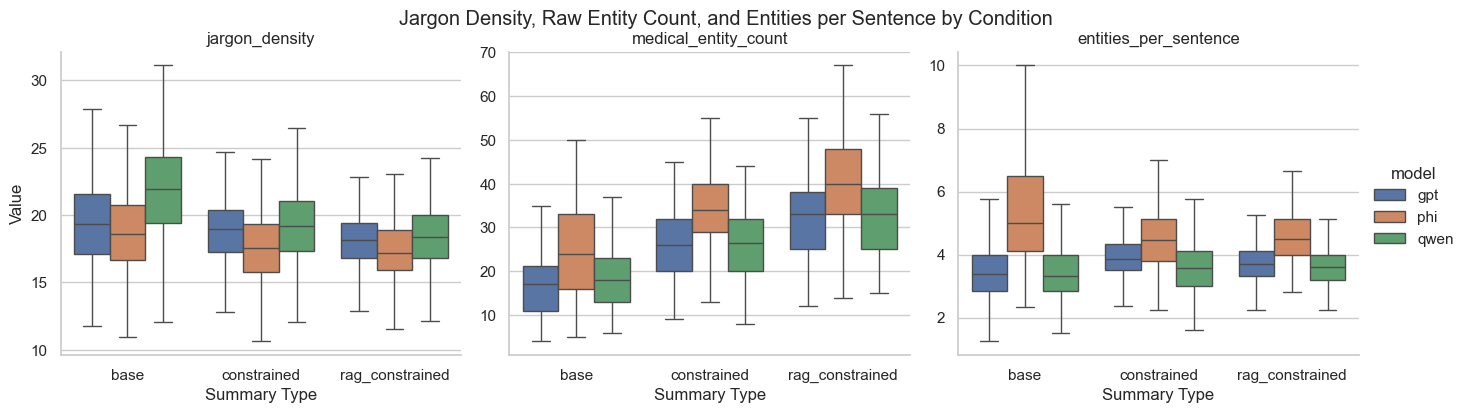

Saved jargon detail rows to: data\readability_metrics\jargon_per_summary.csv
Saved jargon aggregated stats to: data\readability_metrics\jargon_aggregated.csv


In [14]:
def normalize_term(text: str) -> str:
    return re.sub(r"\s+", " ", text.lower()).strip()

def ensure_umls_pipeline(current_nlp):
    # Ensure the scispaCy linker factory is registered in this kernel session.
    try:
        import scispacy  # noqa: F401
        from scispacy.linking import EntityLinker  # noqa: F401
    except ImportError as exc:
        raise ImportError(
            "scispaCy is required for UMLS-linked jargon metrics. Install scispacy and model deps."
        ) from exc

    # Ensure we are using a SciSpaCy pipeline with linker enabled.
    if current_nlp is None:
        current_nlp = spacy.load("en_core_sci_sm")
    if "scispacy_linker" not in current_nlp.pipe_names:
        current_nlp.add_pipe(
            "scispacy_linker",
            config={"resolve_abbreviations": True, "linker_name": "umls"},
        )
    return current_nlp

def extract_medical_jargon_from_doc(doc):
    extracted = []
    seen = set()

    for ent in doc.ents:
        # Keep only entities that map to at least one UMLS concept.
        if not ent._.kb_ents:
            continue
        normalized = normalize_term(ent.text)
        if normalized in seen:
            continue
        extracted.append(ent.text)
        seen.add(normalized)

    return extracted

def calculate_jargon_metrics(text: str, nlp_model):
    """Return density, entities, entity count, sentence count, and entities per sentence."""
    doc = nlp_model(text)
    jargon_terms = extract_medical_jargon_from_doc(doc)
    total_words = len([token for token in doc if not token.is_punct and not token.is_space])
    sentence_count = len([sent for sent in doc.sents if sent.text.strip()])

    if total_words == 0:
        return 0.0, [], 0, sentence_count, 0.0

    entity_count = len(jargon_terms)
    jargon_density = (entity_count / total_words) * 100
    entities_per_sentence = entity_count / sentence_count if sentence_count > 0 else np.nan

    return (
        float(jargon_density),
        jargon_terms,
        int(entity_count),
        int(sentence_count),
        float(entities_per_sentence) if not np.isnan(entities_per_sentence) else np.nan,
    )

print("Loading NLP model with UMLS linker...")
try:
    nlp
except NameError:
    nlp = None
nlp = ensure_umls_pipeline(nlp)

# Build a text dataframe from all models + summary types (same source scope as readability).
text_rows = []
for model in MODEL_DIRS:
    model_dir = BASE_DIR / model
    for summary_type, file_name in SUMMARY_FILES.items():
        file_path = model_dir / file_name
        if not file_path.exists():
            continue

        with file_path.open("r", encoding="utf-8") as f:
            records = json.load(f)

        for rec in records:
            if not isinstance(rec, dict):
                continue
            text = rec.get("patient_summary")
            if not isinstance(text, str) or not text.strip():
                continue

            text_rows.append({
                "model": model,
                "summary_type": summary_type,
                "sample_id": rec.get("sample_id"),
                "patient_summary": text,
            })

df_text = pd.DataFrame(text_rows)

# Compute jargon metrics for every summary across all models and summary types.
jargon_output = df_text["patient_summary"].apply(lambda t: calculate_jargon_metrics(t, nlp))
df_jargon = df_text.copy()
df_jargon["jargon_density"] = jargon_output.apply(lambda x: x[0])
df_jargon["medical_entities"] = jargon_output.apply(lambda x: x[1])
df_jargon["medical_entity_count"] = jargon_output.apply(lambda x: x[2])
df_jargon["sentence_count"] = jargon_output.apply(lambda x: x[3])
df_jargon["entities_per_sentence"] = jargon_output.apply(lambda x: x[4])

jargon_stats = (
    df_jargon.groupby(["model", "summary_type"], as_index=False)
    .agg(
        n=("sample_id", "count"),
        jargon_density_mean=("jargon_density", "mean"),
        jargon_density_std=("jargon_density", "std"),
        medical_entity_count_mean=("medical_entity_count", "mean"),
        medical_entity_count_std=("medical_entity_count", "std"),
        sentence_count_mean=("sentence_count", "mean"),
        sentence_count_std=("sentence_count", "std"),
        entities_per_sentence_mean=("entities_per_sentence", "mean"),
        entities_per_sentence_std=("entities_per_sentence", "std"),
    )
    .sort_values(["summary_type", "model"])
    .reset_index(drop=True)
)

display(
    jargon_stats[[
        "model",
        "summary_type",
        "jargon_density_mean",
        "medical_entity_count_mean",
        "entities_per_sentence_mean",
        "sentence_count_mean",
    ]]
)

print(
    "Note: jargon density (%), raw entity count, and entities-per-sentence can move in different directions "
    "when summaries add explanatory words/sentences around similar jargon loads."
)

# Side-by-side distribution plots for complementary jargon views.
jargon_plot_long = df_jargon.melt(
    id_vars=["model", "summary_type", "sample_id"],
    value_vars=["jargon_density", "medical_entity_count", "entities_per_sentence"],
    var_name="metric",
    value_name="value",
)

g = sns.catplot(
    data=jargon_plot_long,
    kind="box",
    x="summary_type",
    y="value",
    hue="model",
    col="metric",
    col_wrap=3,
    height=4.2,
    aspect=1.1,
    sharey=False,
    showfliers=False,
    legend_out=True,
 )
g.set_titles("{col_name}")
g.set_axis_labels("Summary Type", "Value")
g.fig.subplots_adjust(top=0.88)
g.fig.suptitle("Jargon Density, Raw Entity Count, and Entities per Sentence by Condition")
plt.show()

# Save jargon outputs (self-healing if this cell is run out of order)
try:
    OUTPUT_DIR
except NameError:
    OUTPUT_DIR = Path("data/readability_metrics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

jargon_detail_path = OUTPUT_DIR / "jargon_per_summary.csv"
jargon_agg_path = OUTPUT_DIR / "jargon_aggregated.csv"

# Convert entity lists to pipe-separated text for CSV storage
df_jargon_export = df_jargon.copy()
df_jargon_export["medical_entities"] = df_jargon_export["medical_entities"].apply(
    lambda ents: " | ".join(ents) if ents else ""
 )

df_jargon_export.to_csv(jargon_detail_path, index=False, encoding="utf-8")
jargon_stats.to_csv(jargon_agg_path, index=False, encoding="utf-8")

print(f"Saved jargon detail rows to: {jargon_detail_path}")
print(f"Saved jargon aggregated stats to: {jargon_agg_path}")

In [9]:
# Paired statistical testing plan: Wilcoxon signed-rank + effect sizes + BH-FDR by family.
import numpy as np
import pandas as pd

try:
    from scipy.stats import wilcoxon, rankdata
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scipy"])
    from scipy.stats import wilcoxon, rankdata

def benjamini_hochberg(p_values):
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    if n == 0:
        return p
    order = np.argsort(p)
    ranked = p[order]
    adj_ranked = ranked * n / np.arange(1, n + 1)
    adj_ranked = np.minimum.accumulate(adj_ranked[::-1])[::-1]
    adj_ranked = np.clip(adj_ranked, 0, 1)
    adj = np.empty(n, dtype=float)
    adj[order] = adj_ranked
    return adj

def paired_wilcoxon_with_effects(a, b):
    paired = pd.DataFrame({"a": a, "b": b}).dropna()
    if paired.empty:
        return {
            "n_pairs": 0,
            "n_nonzero": 0,
            "median_diff": np.nan,
            "mean_diff": np.nan,
            "cohens_d_paired": np.nan,
            "effect_size": np.nan,
            "p_raw": np.nan,
            "statistic": np.nan,
        }

    diff = paired["b"] - paired["a"]
    nz = diff[diff != 0]

    if nz.empty:
        return {
            "n_pairs": int(len(paired)),
            "n_nonzero": 0,
            "median_diff": float(np.median(diff)),
            "mean_diff": float(np.mean(diff)),
            "cohens_d_paired": np.nan,
            "effect_size": 0.0,
            "p_raw": 1.0,
            "statistic": 0.0,
        }

    # Wilcoxon signed-rank test (paired, non-parametric).
    try:
        w = wilcoxon(
            paired["a"],
            paired["b"],
            alternative="two-sided",
            zero_method="wilcox",
            correction=False,
            mode="auto",
        )
        p_raw = float(w.pvalue)
        stat = float(w.statistic)
    except Exception:
        p_raw = np.nan
        stat = np.nan

    # Rank-biserial correlation for paired signed ranks.
    ranks = rankdata(np.abs(nz.values), method="average")
    w_pos = ranks[nz.values > 0].sum()
    w_neg = ranks[nz.values < 0].sum()
    denom = w_pos + w_neg
    effect_size = float((w_pos - w_neg) / denom) if denom > 0 else np.nan

    std_diff = float(np.std(diff, ddof=1)) if len(diff) > 1 else np.nan
    cohens_d_paired = float(np.mean(diff) / std_diff) if std_diff and std_diff > 0 else np.nan

    return {
        "n_pairs": int(len(paired)),
        "n_nonzero": int(len(nz)),
        "median_diff": float(np.median(diff)),
        "mean_diff": float(np.mean(diff)),
        "cohens_d_paired": cohens_d_paired,
        "effect_size": effect_size,
        "p_raw": p_raw,
        "statistic": stat,
    }

# Ensure jargon metrics exist in-memory; fallback to saved CSV if needed.
try:
    df_jargon
except NameError:
    try:
        OUTPUT_DIR
    except NameError:
        OUTPUT_DIR = Path("data/readability_metrics")
    jargon_detail_path = OUTPUT_DIR / "jargon_per_summary.csv"
    if not jargon_detail_path.exists():
        raise FileNotFoundError(
            f"Missing jargon table: {jargon_detail_path}. Run jargon metrics cell first."
        )
    df_jargon = pd.read_csv(jargon_detail_path)

merge_cols = ["model", "summary_type", "sample_id", "jargon_density", "medical_entity_count"]
df_for_tests = df.merge(
    df_jargon[merge_cols],
    on=["model", "summary_type", "sample_id"],
    how="left",
    validate="one_to_one",
)

lexical_metric = "mtld" if "mtld" in df_for_tests.columns else "ttr"
metrics_to_test = [
    "smog",
    "fkgl",
    "ari",
    "dale_chall",
    lexical_metric,
    "avg_dep_depth",
    "subordinate_clause_ratio",
    "word_count",
    "jargon_density",
    "medical_entity_count",
]

long_df = df_for_tests[["sample_id", "model", "summary_type"] + metrics_to_test].melt(
    id_vars=["sample_id", "model", "summary_type"],
    var_name="metric",
    value_name="value",
)

summary_type_pairs = [
    ("base", "constrained"),
    ("constrained", "rag_constrained"),
    ("base", "rag_constrained"),
]
model_pairs = [("gpt", "phi"), ("gpt", "qwen"), ("phi", "qwen")]

results = []

# Family 1: within-model, across summary_type.
for model_name in sorted(long_df["model"].dropna().unique()):
    for metric in metrics_to_test:
        temp = long_df[(long_df["model"] == model_name) & (long_df["metric"] == metric)]
        wide = temp.pivot(index="sample_id", columns="summary_type", values="value")
        for a, b in summary_type_pairs:
            if a not in wide.columns or b not in wide.columns:
                continue
            out = paired_wilcoxon_with_effects(wide[a], wide[b])
            out.update({
                "family": "within_model_across_summary_type",
                "model_or_type": model_name,
                "comparison": f"{b} - {a}",
                "metric": metric,
            })
            results.append(out)

# Family 2: within-summary_type, across model.
for summary_name in sorted(long_df["summary_type"].dropna().unique()):
    for metric in metrics_to_test:
        temp = long_df[(long_df["summary_type"] == summary_name) & (long_df["metric"] == metric)]
        wide = temp.pivot(index="sample_id", columns="model", values="value")
        for a, b in model_pairs:
            if a not in wide.columns or b not in wide.columns:
                continue
            out = paired_wilcoxon_with_effects(wide[a], wide[b])
            out.update({
                "family": "within_summary_type_across_model",
                "model_or_type": summary_name,
                "comparison": f"{b} - {a}",
                "metric": metric,
            })
            results.append(out)

results_df = pd.DataFrame(results)

# Benjamini-Hochberg FDR correction done separately per family.
results_df["p_fdr"] = np.nan
for fam in results_df["family"].dropna().unique():
    fam_mask = results_df["family"] == fam
    fam_p = results_df.loc[fam_mask, "p_raw"].astype(float).values
    valid_mask = np.isfinite(fam_p)
    corrected = np.full_like(fam_p, np.nan, dtype=float)
    if valid_mask.any():
        corrected_valid = benjamini_hochberg(fam_p[valid_mask])
        corrected[valid_mask] = corrected_valid
    results_df.loc[fam_mask, "p_fdr"] = corrected

results_df = results_df[[
    "family",
    "model_or_type",
    "comparison",
    "metric",
    "n_pairs",
    "n_nonzero",
    "median_diff",
    "mean_diff",
    "cohens_d_paired",
    "effect_size",
    "statistic",
    "p_raw",
    "p_fdr",
]].sort_values(["family", "model_or_type", "metric", "comparison"]).reset_index(drop=True)

display(results_df.head(20))

print("\nTest table shape:", results_df.shape)
print("Expected rows if all contrasts available: 180")
print("Lexical metric used:", lexical_metric)

sig_summary = (
    results_df.assign(sig_fdr=results_df["p_fdr"] < 0.05)
    .groupby(["family", "metric"], as_index=False)["sig_fdr"]
    .mean()
    .rename(columns={"sig_fdr": "fraction_significant_fdr"})
)
display(sig_summary)

# Save outputs.
try:
    OUTPUT_DIR
except NameError:
    OUTPUT_DIR = Path("data/readability_metrics")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

tests_long_path = OUTPUT_DIR / "paired_wilcoxon_results.csv"
tests_within_model_path = OUTPUT_DIR / "paired_wilcoxon_within_model.csv"
tests_within_type_path = OUTPUT_DIR / "paired_wilcoxon_within_summary_type.csv"

results_df.to_csv(tests_long_path, index=False, encoding="utf-8")
results_df[results_df["family"] == "within_model_across_summary_type"].to_csv(
    tests_within_model_path, index=False, encoding="utf-8"
)
results_df[results_df["family"] == "within_summary_type_across_model"].to_csv(
    tests_within_type_path, index=False, encoding="utf-8"
)

print(f"Saved paired test results: {tests_long_path}")
print(f"Saved within-model family: {tests_within_model_path}")
print(f"Saved within-summary-type family: {tests_within_type_path}")

,family,model_or_type,comparison,metric,n_pairs,n_nonzero,median_diff,mean_diff,cohens_d_paired,effect_size,statistic,p_raw,p_fdr
0,within_model_across_summary_type,gpt,constrained - base,ari,500,500,2.584754,2.623212,1.224890,0.917413,5172.0,1.113835e-70,5.012257e-70
1,within_model_across_summary_type,gpt,rag_constrained - base,ari,500,500,2.491253,2.476189,1.028721,0.851273,9314.0,4.114879e-61,1.371626e-60
2,within_model_across_summary_type,gpt,rag_constrained - constrained,ari,500,500,-0.112037,-0.147023,-0.082669,-0.099513,56393.0,5.385229e-02,5.910617e-02
3,within_model_across_summary_type,gpt,constrained - base,avg_dep_depth,500,492,0.750000,0.696943,0.904917,0.802512,11975.5,1.127846e-53,3.274393e-53
4,within_model_across_summary_type,gpt,rag_constrained - base,avg_dep_depth,500,492,0.714286,0.705112,0.920143,0.814385,11255.5,3.224142e-55,9.672425e-55
5,within_model_across_summary_type,gpt,rag_constrained - constrained,avg_dep_depth,500,487,0.000000,0.008169,0.011748,-0.009754,58834.5,8.520503e-01,8.520503e-01
6,within_model_across_summary_type,gpt,constrained - base,dale_chall,500,500,0.905601,0.931568,1.226797,0.927776,4523.0,3.042928e-72,1.610962e-71
7,within_model_across_summary_type,gpt,rag_constrained - base,dale_chall,500,500,0.796862,0.874675,1.079643,0.892583,6727.0,5.272543e-67,1.898115e-66
8,within_model_across_summary_type,gpt,rag_constrained - constrained,dale_chall,500,500,-0.056875,-0.056893,-0.087614,-0.105469,56020.0,4.101093e-02,4.556770e-02
9,within_model_across_summary_type,gpt,constrained - base,fkgl,500,500,2.584470,2.556514,1.392142,0.951872,3014.0,6.031550e-76,4.523663e-75



Test table shape: (180, 13)
Expected rows if all contrasts available: 180
Lexical metric used: mtld


,family,metric,fraction_significant_fdr
0,within_model_across_summary_type,ari,0.777778
1,within_model_across_summary_type,avg_dep_depth,0.888889
2,within_model_across_summary_type,dale_chall,0.888889
3,within_model_across_summary_type,fkgl,0.888889
4,within_model_across_summary_type,jargon_density,0.888889
5,within_model_across_summary_type,medical_entity_count,1.000000
6,within_model_across_summary_type,mtld,0.888889
7,within_model_across_summary_type,smog,0.888889
8,within_model_across_summary_type,subordinate_clause_ratio,0.888889
9,within_model_across_summary_type,word_count,1.000000


Saved paired test results: data\readability_metrics\paired_wilcoxon_results.csv
Saved within-model family: data\readability_metrics\paired_wilcoxon_within_model.csv
Saved within-summary-type family: data\readability_metrics\paired_wilcoxon_within_summary_type.csv


In [10]:

# --- Diagnostic: trace avg_dep_depth through the pipeline to find where it breaks ---

print("=" * 70)
print("STAGE 1: raw df - non-null avg_dep_depth counts by model/summary_type")
print("=" * 70)
display(
    df.groupby(["model", "summary_type"])["avg_dep_depth"]
      .agg(n="count", n_notna=lambda s: s.notna().sum())
)

print("\n" + "=" * 70)
print("STAGE 2: df_for_tests (post-merge) - same check")
print("=" * 70)
display(
    df_for_tests.groupby(["model", "summary_type"])["avg_dep_depth"]
      .agg(n="count", n_notna=lambda s: s.notna().sum())
)

print("\n" + "=" * 70)
print("STAGE 3: long_df (post-melt) - same check, filtered to avg_dep_depth rows")
print("=" * 70)
dep_long = long_df[long_df["metric"] == "avg_dep_depth"]
display(
    dep_long.groupby("model")["value"]
      .agg(n="count", n_notna=lambda s: s.notna().sum())
)
print("\ndtype of value column for these rows:", dep_long["value"].dtype)

print("\n" + "=" * 70)
print("STAGE 4: the actual wide pivot used inside the test loop, for gpt")
print("=" * 70)
temp_check = long_df[(long_df["model"] == "gpt") & (long_df["metric"] == "avg_dep_depth")]
print("temp_check shape:", temp_check.shape)
print("duplicate (sample_id, summary_type) pairs:",
      temp_check.duplicated(subset=["sample_id", "summary_type"]).sum())

wide_check = temp_check.pivot(index="sample_id", columns="summary_type", values="value")
print("\nwide_check shape:", wide_check.shape)
print("wide_check columns:", list(wide_check.columns))
display(wide_check.head())
print("\nnon-null counts per column:")
print(wide_check.notna().sum())

# --- Now the actual results you asked for ---

print("\n" + "=" * 70)
print("FULL RESULTS TABLE SHAPE + sig_summary")
print("=" * 70)
print("Test table shape:", results_df.shape, "(expected 180)")

with pd.option_context("display.max_rows", None, "display.width", 200):
    print("\n--- Full sig_summary (fraction significant after FDR, by family/metric) ---")
    display(sig_summary)

    print("\n--- Family 1: within_model_across_summary_type, ALL rows ---")
    display(results_df[results_df["family"] == "within_model_across_summary_type"])

    print("\n--- Family 2: within_summary_type_across_model, ALL rows ---")
    display(results_df[results_df["family"] == "within_summary_type_across_model"])

STAGE 1: raw df - non-null avg_dep_depth counts by model/summary_type


n  n_notna
model summary_type                 
gpt   base             500      500
      constrained      500      500
      rag_constrained  500      500
phi   base             500      500
      constrained      500      500
      rag_constrained  500      500
qwen  base             500      500
      constrained      500      500
      rag_constrained  500      500


STAGE 2: df_for_tests (post-merge) - same check


n  n_notna
model summary_type                 
gpt   base             500      500
      constrained      500      500
      rag_constrained  500      500
phi   base             500      500
      constrained      500      500
      rag_constrained  500      500
qwen  base             500      500
      constrained      500      500
      rag_constrained  500      500


STAGE 3: long_df (post-melt) - same check, filtered to avg_dep_depth rows


,n,n_notna
model,,
gpt,1500,1500
phi,1500,1500
qwen,1500,1500


... (4 outputs left out)


--- Family 1: within_model_across_summary_type, ALL rows ---


,family,model_or_type,comparison,metric,n_pairs,n_nonzero,median_diff,mean_diff,cohens_d_paired,effect_size,statistic,p_raw,p_fdr
0,within_model_across_summary_type,gpt,constrained - base,ari,500,500,2.584754,2.623212,1.224890,0.917413,5172.0,1.113835e-70,5.012257e-70
1,within_model_across_summary_type,gpt,rag_constrained - base,ari,500,500,2.491253,2.476189,1.028721,0.851273,9314.0,4.114879e-61,1.371626e-60
2,within_model_across_summary_type,gpt,rag_constrained - constrained,ari,500,500,-0.112037,-0.147023,-0.082669,-0.099513,56393.0,5.385229e-02,5.910617e-02
3,within_model_across_summary_type,gpt,constrained - base,avg_dep_depth,500,492,0.750000,0.696943,0.904917,0.802512,11975.5,1.127846e-53,3.274393e-53
4,within_model_across_summary_type,gpt,rag_constrained - base,avg_dep_depth,500,492,0.714286,0.705112,0.920143,0.814385,11255.5,3.224142e-55,9.672425e-55
5,within_model_across_summary_type,gpt,rag_constrained - constrained,avg_dep_depth,500,487,0.000000,0.008169,0.011748,-0.009754,58834.5,8.520503e-01,8.520503e-01
6,within_model_across_summary_type,gpt,constrained - base,dale_chall,500,500,0.905601,0.931568,1.226797,0.927776,4523.0,3.042928e-72,1.610962e-71
7,within_model_across_summary_type,gpt,rag_constrained - base,dale_chall,500,500,0.796862,0.874675,1.079643,0.892583,6727.0,5.272543e-67,1.898115e-66
8,within_model_across_summary_type,gpt,rag_constrained - constrained,dale_chall,500,500,-0.056875,-0.056893,-0.087614,-0.105469,56020.0,4.101093e-02,4.556770e-02
9,within_model_across_summary_type,gpt,constrained - base,fkgl,500,500,2.584470,2.556514,1.392142,0.951872,3014.0,6.031550e-76,4.523663e-75



--- Family 2: within_summary_type_across_model, ALL rows ---


,family,model_or_type,comparison,metric,n_pairs,n_nonzero,median_diff,mean_diff,cohens_d_paired,effect_size,statistic,p_raw,p_fdr
90,within_summary_type_across_model,base,phi - gpt,ari,500,500,3.626286,4.274980,1.090664,0.937118,3938.0,1.145485e-73,7.363831e-73
91,within_summary_type_across_model,base,qwen - gpt,ari,500,500,-0.109375,-0.279469,-0.138711,-0.136814,54057.0,8.031993e-03,9.388044e-03
92,within_summary_type_across_model,base,qwen - phi,ari,500,500,-4.223369,-4.554449,-1.256415,-0.968319,1984.0,1.580397e-78,1.777947e-77
93,within_summary_type_across_model,base,phi - gpt,avg_dep_depth,500,484,1.166667,1.320157,1.040097,0.911119,5216.0,1.425613e-67,4.934814e-67
94,within_summary_type_across_model,base,qwen - gpt,avg_dep_depth,500,476,0.000000,-0.060326,-0.074352,-0.094983,51371.5,7.253491e-02,7.961149e-02
95,within_summary_type_across_model,base,qwen - phi,avg_dep_depth,500,490,-1.278571,-1.380483,-1.100499,-0.928085,4325.5,6.929810e-71,3.898018e-70
96,within_summary_type_across_model,base,phi - gpt,dale_chall,500,500,0.183597,0.174820,0.183178,0.201964,49977.0,9.116767e-05,1.155647e-04
97,within_summary_type_across_model,base,qwen - gpt,dale_chall,500,500,0.383453,0.402989,0.411784,0.436104,35314.0,2.929770e-17,4.469140e-17
98,within_summary_type_across_model,base,qwen - phi,dale_chall,500,500,0.200072,0.228169,0.234360,0.266427,45940.0,2.444351e-07,3.333205e-07
99,within_summary_type_across_model,base,phi - gpt,fkgl,500,500,2.875484,3.255353,1.001225,0.905198,5937.0,7.368815e-69,3.014515e-68


In [15]:
import html
import re
from IPython.display import display, HTML

def highlight_terms(text: str, terms):
    escaped = html.escape(text)
    unique_terms = sorted({t.strip() for t in terms if t and t.strip()}, key=len, reverse=True)
    for term in unique_terms:
        pattern = re.compile(re.escape(html.escape(term)), flags=re.IGNORECASE)
        escaped = pattern.sub(lambda m: f"<mark>{m.group(0)}</mark>", escaped)
    return escaped

qwen_dir = BASE_DIR / "qwen"
qwen_base_path = qwen_dir / SUMMARY_FILES["base"]
qwen_rag_path = qwen_dir / SUMMARY_FILES["rag_constrained"]

with qwen_base_path.open("r", encoding="utf-8") as f:
    qwen_base_records = json.load(f)
with qwen_rag_path.open("r", encoding="utf-8") as f:
    qwen_rag_records = json.load(f)

base_by_id = {r.get("sample_id"): r.get("patient_summary", "") for r in qwen_base_records if isinstance(r, dict) and r.get("sample_id")}
rag_by_id = {r.get("sample_id"): r.get("patient_summary", "") for r in qwen_rag_records if isinstance(r, dict) and r.get("sample_id")}

shared_ids = sorted(set(base_by_id.keys()) & set(rag_by_id.keys()))
comparison_rows = []

for sample_id in shared_ids:
    base_text = base_by_id[sample_id]
    rag_text = rag_by_id[sample_id]

    if not isinstance(base_text, str) or not base_text.strip() or not isinstance(rag_text, str) or not rag_text.strip():
        continue

    _, base_entities, base_count, base_sent_count, base_eps = calculate_jargon_metrics(base_text, nlp)
    _, rag_entities, rag_count, rag_sent_count, rag_eps = calculate_jargon_metrics(rag_text, nlp)

    if base_count > rag_count:
        comparison_rows.append({
            "sample_id": sample_id,
            "base_text": base_text,
            "rag_text": rag_text,
            "base_entities": base_entities,
            "rag_entities": rag_entities,
            "base_count": base_count,
            "rag_count": rag_count,
            "delta_count": base_count - rag_count,
            "base_entities_per_sentence": base_eps,
            "rag_entities_per_sentence": rag_eps,
        })

comparison_df = pd.DataFrame(comparison_rows).sort_values(["delta_count", "base_count"], ascending=False)
top_10 = comparison_df.head(10).reset_index(drop=True)

print(f"Found {len(comparison_df)} sample IDs where qwen base has more jargon entities than qwen rag_constrained.")
print("Showing top 10 examples by entity count gap.")

for i, row in top_10.iterrows():
    base_html = highlight_terms(row["base_text"], row["base_entities"])
    rag_html = highlight_terms(row["rag_text"], row["rag_entities"])

    block = f"""
    <div style='border:1px solid #d9d9d9; border-radius:8px; padding:12px; margin:12px 0;'>
      <h4 style='margin:0 0 8px 0;'>Example {i+1} | Sample ID: {row['sample_id']}</h4>
      <p style='margin:0 0 8px 0;'><b>Base entities:</b> {int(row['base_count'])} | <b>RAG entities:</b> {int(row['rag_count'])} | <b>Delta:</b> {int(row['delta_count'])}</p>
      <p style='margin:0 0 12px 0;'><b>Base entities/sentence:</b> {row['base_entities_per_sentence']:.2f} | <b>RAG entities/sentence:</b> {row['rag_entities_per_sentence']:.2f}</p>
      <div style='display:grid; grid-template-columns:1fr 1fr; gap:12px;'>
        <div style='padding:10px; background:#fff8f0; border-radius:6px;'>
          <b>Qwen Base</b>
          <p style='margin-top:8px; white-space:pre-wrap; line-height:1.5;'>{base_html}</p>
        </div>
        <div style='padding:10px; background:#f0fff4; border-radius:6px;'>
          <b>Qwen RAG-Constrained</b>
          <p style='margin-top:8px; white-space:pre-wrap; line-height:1.5;'>{rag_html}</p>
        </div>
      </div>
    </div>
    """
    display(HTML(block))

Found 10 sample IDs where qwen base has more jargon entities than qwen rag_constrained.
Showing top 10 examples by entity count gap.
